# Pythia-160m seed identity: which models share an initialization and a data order

This notebook reads the output of `scripts/check_pythia_seed_identity.py` (canonical code: `models/seed_identity.py`, `models/seed_identity_io.py`). It asks two questions of every 160m model we train from: does it start from the same weights as another model, and does it see the same training data in the same order?

In [1]:
RUN_NAME = "all_models_exact_inputpos_20260916"

In [2]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.config import resolve_roots

REPO, _ = bootstrap()
OUTPUT_ROOT, _ = resolve_roots()
FIG = REPO / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
rec = json.loads((OUTPUT_ROOT / "analysis" / "seed_identity" / RUN_NAME / "identity.json").read_text())
MODELS, WINDOWS = rec["models"], rec["windows"]
IDX = {m: i for i, m in enumerate(MODELS)}
print(f"{len(MODELS)} models, windows {WINDOWS}, method {rec['method']}, init step {rec['init_step']}")

26 models, windows ['1->2', '2->4', '4->8', '8->16', '16->32', '32->64'], method exact, init step 1


## 1. What the check is

**Models.** One row per model. **label** is the short name used throughout; **source** is the Hugging Face repo (kind `hf`) or the native gpt-neox checkpoint directory (kind `native`); **corpus** is the training corpus the check assumes (`pile` = preshuffled Pile, `dclm` = DCLM).

In [3]:
pd.DataFrame([{"label": m, "kind": s["kind"], "source": s["source"], "corpus": s["corpus"]}
              for m, s in rec["provenance"]["sources"].items()])

,label,kind,source,corpus
0,orig,hf,EleutherAI/pythia-160m,pile
1,ds1,hf,EleutherAI/pythia-160m-data-seed1,pile
2,ds2,hf,EleutherAI/pythia-160m-data-seed2,pile
3,ds3,hf,EleutherAI/pythia-160m-data-seed3,pile
4,ws1,hf,EleutherAI/pythia-160m-weight-seed1,pile
5,ws2,hf,EleutherAI/pythia-160m-weight-seed2,pile
6,ws3,hf,EleutherAI/pythia-160m-weight-seed3,pile
7,fs1,hf,EleutherAI/pythia-160m-seed1,pile
8,fs2,hf,EleutherAI/pythia-160m-seed2,pile
9,fs3,hf,EleutherAI/pythia-160m-seed3,pile


**Init test.** At the init step (step 1, the true starting point of the released checkpoints) we compare all 148 floating-point tensors of two models by value. Two models share an initialization when all 148 are equal; the relation is closed transitively into groups.

**Data-order test.** Between checkpoints $a \to b$ an input-embedding row gets a gradient only if its token is fed as an input; the padding rows (§8), which are never inputs, serve as the control.

*Untouched, precisely.* Row $r$ is untouched over window $a \to b$ iff all 768 of its values are equal between the two checkpoints, compared after an exact fp16→fp64 cast, i.e. fp16 value equality. The only difference from byte equality is that $-0.0 = +0.0$ (fp16 rounding can flip the sign of a zero). A row is *touched* if any single value differs, even by one fp16 step ($2.4\times10^{-7}$). What this detects is the absence of any visible gradient update.

*Window semantics.* Adam momentum keeps moving a row for many steps after its token was last an input, so a row untouched over $a \to b$ means the token was never an input in batches $[0, b)$, not just in $[a, b)$. The ground truth is therefore cumulative.

*Limits.* (a) An update smaller than one fp16 step on every value rounds away and the row looks untouched (ws1, token 49222 at 1→2; see §5). (b) Weight decay rescales every row every step. In windows up to 32→64 it is below fp16 precision, which the padding-row control guarantees (27/27 bitwise equal everywhere, §8). In long windows decay is visible: exact equality calls every row touched and the padding-row control marks the window INCONCLUSIVE; there the residual criterion with a fitted scale (§8) is the right test.

Let $U_A$ be the untouched-token set of model $A$ in a window. Two models are compared by the Jaccard index

$$J = \frac{|U_A \cap U_B|}{|U_A \cup U_B|}.$$

Two models share a data order when, in every conclusive window $1\to2, 2\to4, \dots, 32\to64$, their untouched sets differ by at most 5 token ids (pair verdict SHARED if identical, SHARED_WITH_EXCEPTIONS if 1–5 ids differ, all listed); the allowance absorbs fp16 rounding that can leave a touched row bitwise unchanged. A group must be a clique: every pair in it satisfies the rule, otherwise it is reported as non-transitive.

**Pile ground truth.** Pythia's batch $s$ is records $[1024 s, 1024 (s+1))$ of the preshuffled Pile, each 2049 tokens. gpt-neox (`megatron/training.py::_get_batch`) feeds positions 0–2047 as inputs and positions 1–2048 as labels, (`tokens = tokens_[:, :-1]`), so position 2048 of each record is a label only and never touches an input embedding: *seen* means occurring at input positions 0–2047. Through batch 64, token 20746 was the only token that occurred solely at label position 2048 (verified 09-16, not in the JSON). The true untouched set at window $a \to b$ is the tokens that never occur at input positions 0–2047 of records $[0, 1024\,b)$.

**Verdicts** (model vs. Pile truth in one window):
- **MATCH** — untouched set equals the truth.
- **MATCH_WITH_EXCEPTIONS** — at most 5 differing token ids, all listed.
- **MISMATCH** — more than 5 differing ids: not the Pile order.
- **FAR_FROM_PILE** — DCLM-corpus models with $J < 0.9$ against the Pile truth (the expected outcome).

In [4]:
p = rec["provenance"]
print(f"host {p['host']}, git {p['git_sha'][:10]}, run {RUN_NAME}, created {rec['created_utc']}, "
      f"ground-truth params {rec.get('ground_truth_params')}")

host soar-subliminal-1, git eca594a599, run all_models_exact_inputpos_20260916, created 2026-09-16T23:40:53Z, ground-truth params {'max_mismatches': 5, 'far_from_pile_jaccard': 0.9}


## 2. Initialization groups

One row per group of models whose 148 tensors are all equal at step 1. **group** numbers groups; **models** lists members; **released init** names the Hugging Face repo(s) in the group, i.e. which published model's initialization the group carries (native runs have none of their own).

In [5]:
SRC = rec["provenance"]["sources"]
def released(ms):
    hf = [SRC[m]["source"] for m in ms if SRC[m]["kind"] == "hf"]
    return ", ".join(hf) if hf else "(none: native only)"
init_groups = pd.DataFrame([{"group": i + 1, "models": ", ".join(g), "released init": released(g)}
                            for i, g in enumerate(rec["init"]["classes"])])
print(f"non-transitive init triples: {rec['init']['non_transitive']}")
init_groups

non-transitive init triples: []


,group,models,released init
0,1,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...","EleutherAI/pythia-160m, EleutherAI/pythia-160m..."
1,2,"fs1, wc1, dclm_s1, dclm_s1_cold",EleutherAI/pythia-160m-seed1
2,3,"fs2, wc2, dclm_s2",EleutherAI/pythia-160m-seed2
3,4,"fs3, ws3pile",EleutherAI/pythia-160m-seed3
4,5,fs4,EleutherAI/pythia-160m-seed4
5,6,fs5,EleutherAI/pythia-160m-seed5
6,7,fs6,EleutherAI/pythia-160m-seed6
7,8,fs7,EleutherAI/pythia-160m-seed7
8,9,fs8,EleutherAI/pythia-160m-seed8
9,10,fs9,EleutherAI/pythia-160m-seed9


## 3. Data-order groups

One row per group of models whose untouched-row sets differ by at most 5 ids in every window (see §1). **group** numbers groups; **models** lists members.

In [6]:
print(f"non-transitive order triples: {rec['order']['non_transitive']}")
pd.DataFrame([{"group": i + 1, "models": ", ".join(g)} for i, g in enumerate(rec["order"]["classes"])])

non-transitive order triples: []


,group,models
0,1,"orig, ws1, ws2, ws3, wc1, wc2, rerun, ws3pile"
1,2,ds1
2,3,ds2
3,4,ds3
4,5,fs1
5,6,fs2
6,7,fs3
7,8,fs4
8,9,fs5
9,10,fs6


## 4. Pairwise Jaccard across early windows

One row per window $a \to b$. Each column is one model pair; the value is $J$ between their untouched-row sets in that window ($1$ = identical).

In [7]:
PAIRS = [("orig", "ws1"), ("orig", "ws2"), ("orig", "ds1"), ("ds1", "ds2"), ("orig", "fs1"),
         ("fs1", "fs2"), ("orig", "orderb"), ("orig", "dclm_main"), ("dclm_main", "dclm_main_cold")]
JM = {w: np.array(rec["order"]["jaccard_matrices"][w], dtype=float) for w in WINDOWS}
pd.DataFrame({f"{x}–{y}": [JM[w][IDX[x], IDX[y]] for w in WINDOWS] for x, y in PAIRS},
             index=pd.Index(WINDOWS, name="window")).round(4)

,orig–ws1,orig–ws2,orig–ds1,ds1–ds2,orig–fs1,fs1–fs2,orig–orderb,orig–dclm_main,dclm_main–dclm_main_cold
window,,,,,,,,,
1->2,0.9994,1.0,0.3042,0.2847,0.2973,0.3139,0.2924,0.1550,1.0
2->4,1.0000,1.0,0.5043,0.4326,0.4700,0.4531,0.4592,0.1461,1.0
4->8,1.0000,1.0,0.5868,0.5884,0.6010,0.6258,0.5522,0.1668,1.0
8->16,1.0000,1.0,0.6814,0.6919,0.6935,0.7176,0.6944,0.1992,1.0
16->32,1.0000,1.0,0.8025,0.7957,0.8168,0.8030,0.8019,0.2467,1.0
32->64,1.0000,1.0,0.8989,0.8705,0.8652,0.8415,0.8759,0.3164,1.0


One row per window. **same-order J (min–max)** is the range of $J$ over all pairs of distinct models in the same data-order group; **different-order J (min–max)** is the range over pairs in different groups; **n same / n different** count those pairs.

In [8]:
grp = {m: i for i, g in enumerate(rec["order"]["classes"]) for m in g}
rows = []
for w in WINDOWS:
    same, diff = [], []
    for i, x in enumerate(MODELS):
        for y in MODELS[i + 1:]:
            (same if grp.get(x, x) == grp.get(y, y) else diff).append(JM[w][IDX[x], IDX[y]])
    rows.append({"window": w, "same-order J (min–max)": f"{np.nanmin(same):.4f}–{np.nanmax(same):.4f}",
                 "n same": len(same),
                 "different-order J (min–max)": f"{np.nanmin(diff):.4f}–{np.nanmax(diff):.4f}",
                 "n different": len(diff)})
pd.DataFrame(rows).set_index("window")

,same-order J (min–max),n same,different-order J (min–max),n different
window,,,,
1->2,0.9994–1.0000,38,0.1361–0.3244,287
2->4,1.0000–1.0000,38,0.1261–0.5043,287
4->8,1.0000–1.0000,38,0.1465–0.6258,287
8->16,1.0000–1.0000,38,0.1850–0.7433,287
16->32,1.0000–1.0000,38,0.2407–0.8438,287
32->64,1.0000–1.0000,38,0.3071–0.9018,287


## 5. Ground truth vs. the Pile

One row per model, one column per window; each cell is that model's verdict against the Pile truth, abbreviated: **M** = MATCH, **M+k** = MATCH_WITH_EXCEPTIONS with $k$ differing ids, **X(n)** = MISMATCH with $n$ differing ids, **FAR** = FAR_FROM_PILE, **–** = not evaluated. The **corpus** column is the assumed training corpus.

In [9]:
def short(g):
    v = g["verdict"]
    n = g["n_run_minus_truth"] + g["n_truth_minus_run"]
    return {"MATCH": "M", "MATCH_WITH_EXCEPTIONS": f"M+{n}", "MISMATCH": f"X({n})",
            "FAR_FROM_PILE": "FAR"}.get(v, v)
GT = rec["ground_truth"]
gt = pd.DataFrame([{"model": m, "corpus": SRC[m]["corpus"],
                    **{w: short(GT[m][w]) if m in GT and w in GT[m] else "–" for w in WINDOWS}}
                   for m in MODELS]).set_index("model")
gt

,corpus,1->2,2->4,4->8,8->16,16->32,32->64
model,,,,,,,
orig,pile,M,M,M,M,M,M
ds1,pile,X(1814),X(518),X(262),X(137),X(64),X(28)
ds2,pile,X(1875),X(590),X(240),X(127),X(61),X(36)
ds3,pile,X(1785),X(560),X(280),X(129),X(61),X(34)
ws1,pile,M+1,M,M,M,M,M
ws2,pile,M,M,M,M,M,M
ws3,pile,M,M,M,M,M,M
fs1,pile,X(1792),X(557),X(249),X(133),X(59),X(38)
fs2,pile,X(1734),X(572),X(268),X(121),X(78),X(49)


One row per (window, token id) that makes some Pile model MATCH_WITH_EXCEPTIONS. **window** is $a \to b$; **token id** is the differing id; **models** are the Pile-corpus models with that exception.

In [10]:
exc = [{"window": w, "token id": int(t), "models": ", ".join(ms)}
       for w, d in rec.get("ground_truth_exceptions", {}).items() for t, ms in d.items()]
pd.DataFrame(exc, columns=["window", "token id", "models"])

,window,token id,models
0,1->2,49222,ws1


### Two tokens, case by case (verified 09-16)

**Token 20746 (' intrig') — the old ground-truth bug, now fixed.** In batches 0–1 it occurs once, at position 2048 of record 520. Position 2048 is a label, never an input, so its embedding row is not updated at step 1→2, and every Pile-order model leaves it untouched. The earlier ground truth counted all 2049 positions as seen, which put 20746 in the "seen" set and flagged every Pile-order model at 1→2. The row does change at 2→4, where the token appears 6 times as input.

**Token 49222 (' odon') — an fp16 rounding case.** It has exactly one input occurrence in batches 0–1 (record 88, position 1510), so the truth says its row is touched at 1→2. In orig, ws2, ws3 and rerun the step-2 update is a single fp16 quantum ($2.4\times10^{-7}$) on 2–3 elements; in ws1 it rounds to zero, so ws1 reports the row as untouched. For comparison, the median token seen exactly once changes 11 elements. This is a rounding artefact, not a data-order difference.

## 6. Heatmaps

Models are ordered by data-order group (Jaccard panels) or init group (init panel); lines separate groups.

saved notebooks/figures/pythia_seed_identity_heatmaps_20260916.png


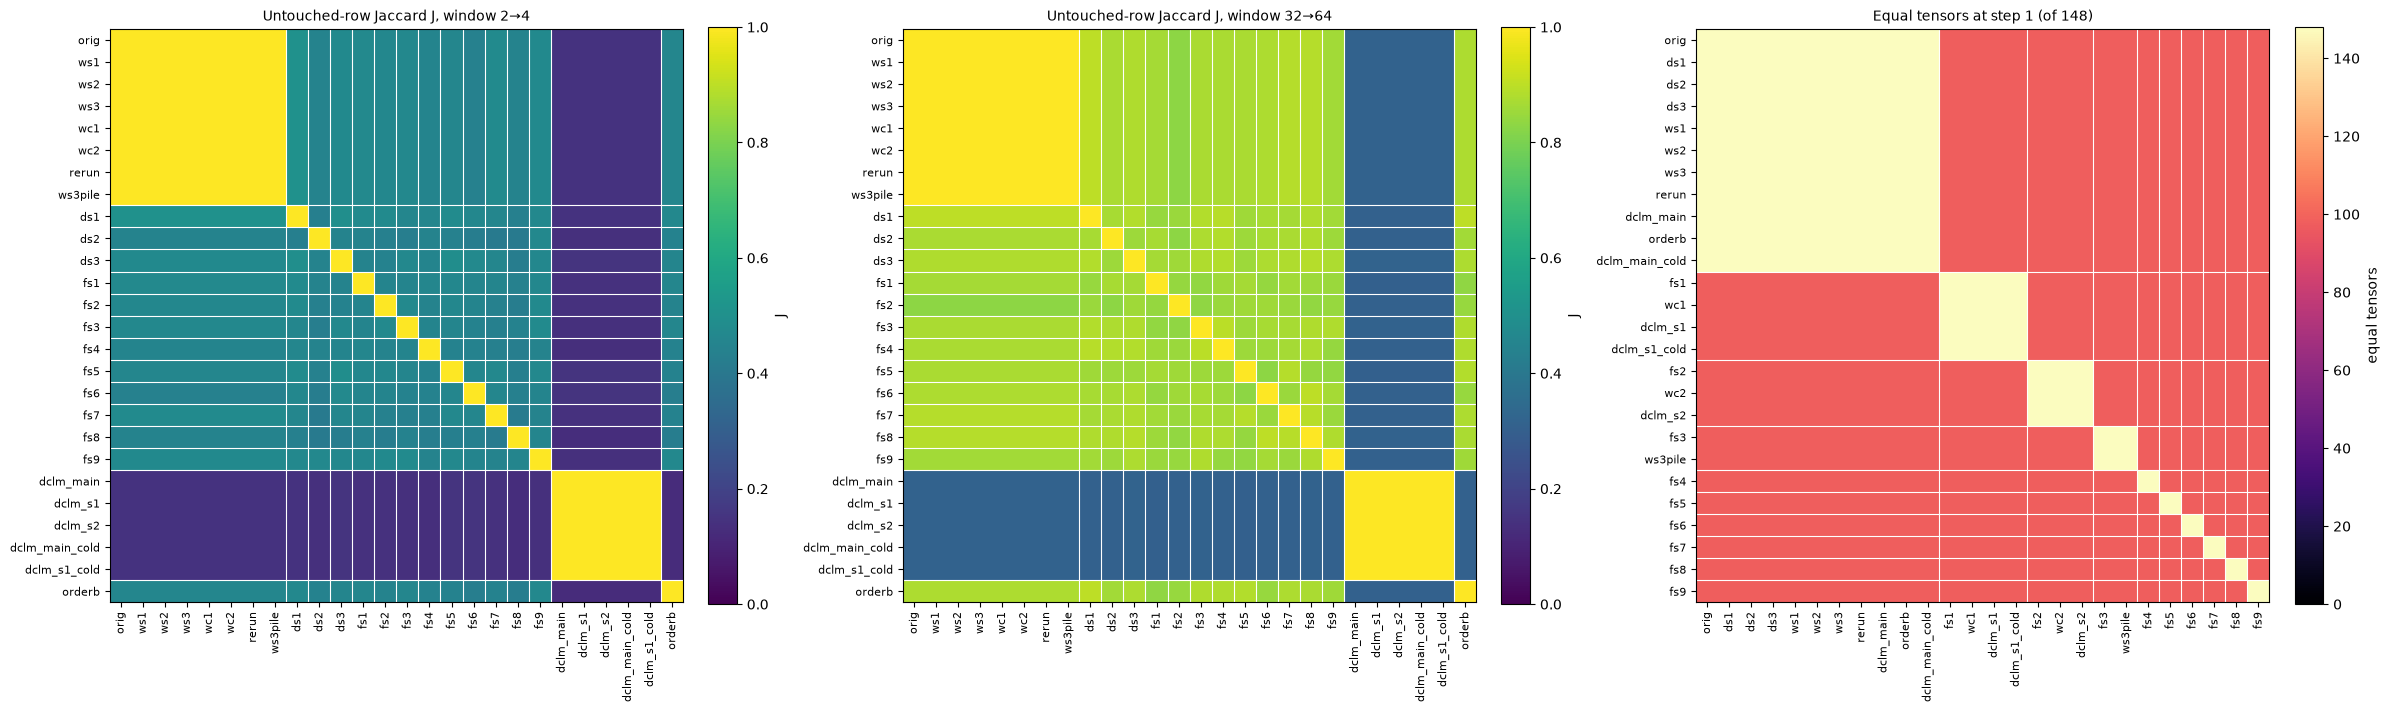

In [11]:
def ordered(classes):
    return [m for g in classes for m in g]

def heat(ax, M, labels, classes, title, cbar, vmin=None, vmax=None, cmap="viridis"):
    idx = [IDX[m] for m in labels]
    im = ax.imshow(M[np.ix_(idx, idx)], vmin=vmin, vmax=vmax, cmap=cmap)
    ax.set_xticks(range(len(labels)), labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    edge = np.cumsum([len(g) for g in classes])[:-1] - 0.5
    for e in edge:
        ax.axhline(e, color="w", lw=0.8)
        ax.axvline(e, color="w", lw=0.8)
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=cbar)

oc, ic = rec["order"]["classes"], rec["init"]["classes"]
n_tensors = 148
INIT = np.array(rec["init"]["fraction_equal_matrix"], dtype=float) * n_tensors
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
heat(axes[0], JM["2->4"], ordered(oc), oc, "Untouched-row Jaccard J, window 2→4", "J", 0, 1)
heat(axes[1], JM["32->64"], ordered(oc), oc, "Untouched-row Jaccard J, window 32→64", "J", 0, 1)
heat(axes[2], INIT, ordered(ic), ic, f"Equal tensors at step {rec['init_step']} (of {n_tensors})",
     "equal tensors", 0, n_tensors, cmap="magma")
fig.tight_layout()
out = FIG / "pythia_seed_identity_heatmaps_20260916.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
print(f"saved {out.relative_to(REPO)}")

## 7. ws1 is in orig's data-order group, with one 1→2 exception

ws1's untouched set differs from orig's by exactly one id, 49222, at window 1→2 (the fp16 rounding case above), so $J = 0.999$ there and $J = 1.000$ in every later window. That is within the 5-id allowance, so ws1 sits in orig's group, and the exception is listed below.

One row per (window, token id) that makes some model pair SHARED_WITH_EXCEPTIONS. **window** is $a \to b$; **token id** is the id untouched in one model of the pair but not the other; **n pairs** counts such pairs; **pairs** lists them as `x|y`.

In [12]:
print(f"order allowance: {rec['order'].get('max_mismatches')} ids")
pd.DataFrame([{"window": w, "token id": int(t), "n pairs": len(ps), "pairs": ", ".join(ps)}
              for w, d in rec["order"].get("exceptions", {}).items() for t, ps in d.items()],
             columns=["window", "token id", "n pairs", "pairs"])

order allowance: 5 ids


,window,token id,n pairs,pairs
0,1->2,49222,7,"orig|ws1, ws1|ws2, ws1|ws3, ws1|wc1, ws1|wc2, ..."


In [13]:
print("ws1 vs orig J by window: " + ", ".join(f"{w} {JM[w][IDX['orig'], IDX['ws1']]:.4f}" for w in WINDOWS))

ws1 vs orig J by window: 1->2 0.9994, 2->4 1.0000, 4->8 1.0000, 8->16 1.0000, 16->32 1.0000, 32->64 1.0000


## 8. Padding rows: weight-decay-only ancestry

**What padding rows are.** The Pythia tokenizer has 50,277 tokens (ids 0–50276). gpt-neox sets `make_vocab_size_divisible_by = 128`, which rounds the embedding matrix up to 50,304 rows. Rows 50277–50303 are the 27 *padding rows*: randomly initialised, belonging to no token, never looked up as an input, never receiving a gradient, and changed only by weight decay. They are not the tokenizer's `<|padding|>` token (id 1), which is an ordinary vocabulary row. A checkpoint's padding rows are therefore a scaled copy of the init they started from, $w_t = c\,w_0$. For each row we fit

$$c = \frac{\langle w_0, w_t\rangle}{\|w_0\|^2}, \qquad r = \frac{\|w_t - c\,w_0\|}{\|w_0\|}, \qquad \|w_t - c\,w_0\| = \|w_t\|\sin\theta,$$

where $\theta$ is the angle between $w_0$ and $w_t$. A pure-decay descendant has $\cos\theta = 1$ and $r$ at fp16 rounding level; rows of an unrelated init give $\cos\theta \approx 0$. This makes padding rows a clean ancestry marker over the whole run, where the untouched-row test only works in early windows.

**Residual and cosine are the same measurement.** From the identity above, $r = \frac{\|w_t\|}{\|w_0\|}\sin\theta$, and $1-\cos\theta \approx \tfrac12\sin^2\theta$. Both measure the angle between $w_0$ and $w_t$, so both need a threshold above the fp16 floor. The table below shows why a fixed cosine threshold cannot replace exact equality in early windows. Source: `padding_ancestry.json` from `scripts/check_pythia_padding_ancestry.py` in the same run dir.

One row per case (numbers verified 09-16, not read from the JSON). **case** is the rows and window compared; **residual** is $r$; **1−cos** is $1-\cos\theta$; **outcome with cos ≥ 0.999999** is the verdict a fixed cosine threshold gives and whether it is correct.

In [14]:
pd.DataFrame([
    {"case": "padding rows, step 1→143000 (decay only)", "residual": "2.6e-6", "1−cos": "≈2e-8",
     "outcome with cos ≥ 0.999999": "untouched ✓"},
    {"case": "input rows, step 1→143000", "residual": "large", "1−cos": "≥ 0.35 (cos ≤ 0.65)",
     "outcome with cos ≥ 0.999999": "touched ✓"},
    {"case": "input rows, step 1→2", "residual": "1e-6 – 2.5e-6", "1−cos": "≈5e-13 – 3e-12",
     "outcome with cos ≥ 0.999999": "untouched ✗ (all ~48,600 seen rows)"},
]).set_index("case")

,residual,1−cos,outcome with cos ≥ 0.999999
case,,,
"padding rows, step 1→143000 (decay only)",2.6e-6,≈2e-8,untouched ✓
"input rows, step 1→143000",large,≥ 0.35 (cos ≤ 0.65),touched ✓
"input rows, step 1→2",1e-6 – 2.5e-6,≈5e-13 – 3e-12,"untouched ✗ (all ~48,600 seen rows)"


**Conclusion.** Early windows use exact equality: no threshold, valid whenever the padding rows are bitwise equal. Long windows use the residual (equivalently the angle) with a threshold calibrated from the padding rows' own leftover, plus a check that untouched rows share the padding rows' common scale.

In [15]:
PA = json.loads((OUTPUT_ROOT / "analysis" / "seed_identity" / RUN_NAME / "padding_ancestry.json").read_text())
p = PA["provenance"]
print(f"padding ancestry: host {p['host']}, git {p['git_sha'][:10]}, created {PA['created_utc']}")

padding ancestry: host soar-subliminal-1, git eca594a599, created 2026-09-16T23:37:36Z


One row per model. **latest step** is the last checkpoint available offline (HF step 143000; native runs their largest saved step). The **vs step1** columns compare the latest padding rows with the model's own step-1 rows; the **vs step0** columns with its own step-0 rows. **cos min** is the smallest per-row cosine over the 27 rows; **scale** is the fitted $c$ range (min–max); **resid max** is the largest $r$.

In [16]:
def pad_cols(v, tag):
    if v is None:
        return {f"{tag} cos min": np.nan, f"{tag} scale": "–", f"{tag} resid max": np.nan}
    return {f"{tag} cos min": v["cos_min"], f"{tag} scale": f"{v['scale_min']:.5f}–{v['scale_max']:.5f}",
            f"{tag} resid max": v["resid_max"]}
pd.DataFrame([{"model": m, "latest step": PA["per_model"][m]["latest_step"],
               **pad_cols(PA["per_model"][m]["latest_vs_step1"], "vs step1"),
               **pad_cols(PA["per_model"][m]["latest_vs_step0"], "vs step0")}
              for m in PA["models"]]).set_index("model")

,latest step,vs step1 cos min,vs step1 scale,vs step1 resid max,vs step0 cos min,vs step0 scale,vs step0 resid max
model,,,,,,,
orig,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003
ds1,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003
ds2,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003
ds3,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003
ws1,143000,1.0,0.01180–0.01180,0.000003,-0.062827,-0.00073–0.00109,0.012986
ws2,143000,1.0,0.01180–0.01180,0.000003,-0.047597,-0.00055–0.00090,0.012859
ws3,143000,1.0,0.01180–0.01180,0.000003,-0.077232,-0.00089–0.00096,0.013352
fs1,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003
fs2,143000,1.0,0.01180–0.01180,0.000003,1.000000,0.01180–0.01180,0.000003


Ancestry matrix: row = a model's latest checkpoint, column = a model's step-1 init; value = smallest per-row cosine of the padding rows. Models are ordered by init group (§2).

saved notebooks/figures/pythia_padding_ancestry_20260916.png


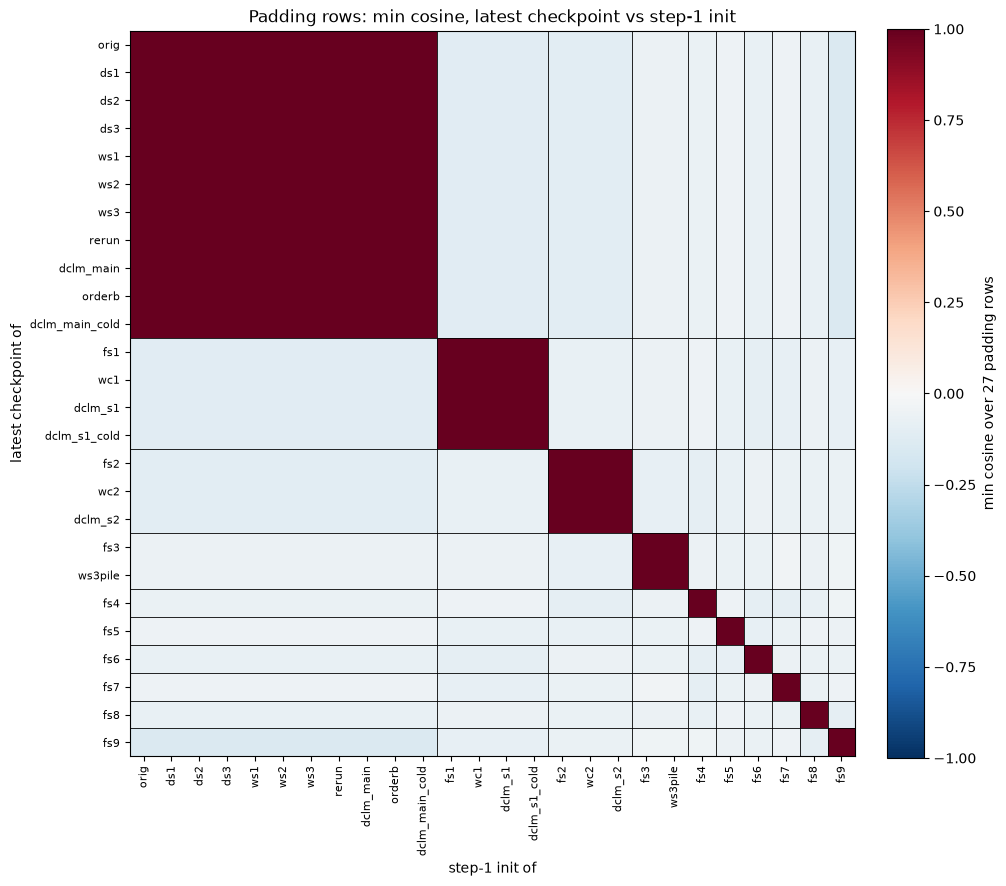

In [17]:
PIDX = {m: i for i, m in enumerate(PA["models"])}
COS = np.array(PA["ancestry"]["cos_min"], dtype=float)
lab = ordered(ic)
k = [PIDX[m] for m in lab]
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(COS[np.ix_(k, k)], vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(lab)), lab, rotation=90, fontsize=8)
ax.set_yticks(range(len(lab)), lab, fontsize=8)
for e in np.cumsum([len(g) for g in ic])[:-1] - 0.5:
    ax.axhline(e, color="k", lw=0.6)
    ax.axvline(e, color="k", lw=0.6)
ax.set_xlabel("step-1 init of")
ax.set_ylabel("latest checkpoint of")
ax.set_title("Padding rows: min cosine, latest checkpoint vs step-1 init")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="min cosine over 27 padding rows")
fig.tight_layout()
out = FIG / "pythia_padding_ancestry_20260916.png"
fig.savefig(out, dpi=130, bbox_inches="tight")
print(f"saved {out.relative_to(REPO)}")

One row per model. **descends from init of** lists the models whose step-1 padding rows have min cosine ≥ 0.999 with this model's latest padding rows; **own init group** says whether that list equals the model's init group from §2; **best other cos** is the highest min cosine to any init outside that list.

In [18]:
igrp = {m: set(g) for g in ic for m in g}
rows = []
for m in PA["models"]:
    d = PA["ancestry"]["descends_from_init_of"][m]
    other = [COS[PIDX[m], PIDX[y]] for y in PA["models"] if d is not None and y not in d]
    rows.append({"model": m, "descends from init of": ", ".join(d) if d else "–",
                 "own init group": d is not None and set(d) == igrp.get(m, {m}),
                 "best other cos": max(other) if other else np.nan})
anc = pd.DataFrame(rows).set_index("model")
print(f"models descending exactly from their own init group: {int(anc['own init group'].sum())}/{len(anc)}")
anc

models descending exactly from their own init group: 26/26


,descends from init of,own init group,best other cos
model,,,
orig,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047601
ds1,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047594
ds2,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047602
ds3,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047596
ws1,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047600
ws2,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047597
ws3,"orig, ds1, ds2, ds3, ws1, ws2, ws3, rerun, dcl...",True,-0.047599
fs1,"fs1, wc1, dclm_s1, dclm_s1_cold",True,-0.051235
fs2,"fs2, wc2, dclm_s2",True,-0.061440


One row per model, one column per early window $a \to b$; each cell is the number of padding rows (of 27) that are bitwise equal at $a$ and $b$. 27/27 everywhere is why exact row equality is a valid untouched criterion in these windows.

In [19]:
pd.DataFrame({w: {m: (v[w]["n_exact_equal"] if v[w] else None) for m, v in PA["windows_pad"].items()}
              for w in PA["windows"]})

,1->2,2->4,4->8,8->16,16->32,32->64
orig,27,27,27,27,27,27
ds1,27,27,27,27,27,27
ds2,27,27,27,27,27,27
ds3,27,27,27,27,27,27
ws1,27,27,27,27,27,27
ws2,27,27,27,27,27,27
ws3,27,27,27,27,27,27
fs1,27,27,27,27,27,27
fs2,27,27,27,27,27,27
fs3,27,27,27,27,27,27


**Untouched from step 1 to the end.** With the residual criterion at $r \le 3\times10^{-6}$ (exact equality and $10^{-6}$ find nothing, and their padding-row control correctly fails, because decay moves every row), the tokens untouched between step 1 and step 143000 are compared below for orig and ws1–3. Verified 09-16: the same 214 tokens in all four, fitted scale 0.01180, and the next-highest cosine among other rows is 0.65.

One row per criterion for window step 1→143000 in orig (verified 09-16, not read from the JSON). **criterion** is the untouched rule; **n untouched** is how many rows it calls untouched; **padding-row control** says whether all 27 padding rows pass it; **note** gives the scale or reason.

In [20]:
pd.DataFrame([
    {"criterion": "exact equality", "n untouched": 0, "padding-row control": "fails", "note": "decay moves every row"},
    {"criterion": "residual r ≤ 1e-6", "n untouched": 0, "padding-row control": "fails",
     "note": "padding-row leftover 2.6e-6"},
    {"criterion": "residual r ≤ 3e-6 … 1e-3", "n untouched": 214, "padding-row control": "ok", "note": "fitted scale 0.01180"},
    {"criterion": "cos ≥ 0.999999", "n untouched": 214, "padding-row control": "ok",
     "note": "same 214; next-highest cos 0.65"},
]).set_index("criterion")

,n untouched,padding-row control,note
criterion,,,
exact equality,0,fails,decay moves every row
residual r ≤ 1e-6,0,fails,padding-row leftover 2.6e-6
residual r ≤ 3e-6 … 1e-3,214,ok,fitted scale 0.01180
cos ≥ 0.999999,214,ok,same 214; next-highest cos 0.65


In [21]:
U = {m: PA["per_model"][m]["latest_untouched"] for m in ["orig", "ws1", "ws2", "ws3"]}
sets = {m: set(u["ids"]) for m, u in U.items() if u}
print(f"step1→latest untouched (tol {U['orig']['tol']}): sizes {{{', '.join(f'{m}: {len(s)}' for m, s in sets.items())}}}, "
      f"identical across all: {len({frozenset(s) for s in sets.values()}) == 1}")
pd.DataFrame([{"model": m, "n untouched": len(u["ids"]), "padding-row control ok": u["pad_control_ok"],
               "scale min": u["scale_min"], "scale max": u["scale_max"]} for m, u in U.items() if u])

step1→latest untouched (tol 3e-06): sizes {orig: 214, ws1: 214, ws2: 214, ws3: 214}, identical across all: True


,model,n untouched,padding-row control ok,scale min,scale max
0,orig,214,True,0.011802,0.011803
1,ws1,214,True,0.011803,0.011804
2,ws2,214,True,0.011802,0.011803
3,ws3,214,True,0.011801,0.011802


### Weight-decay scale differs between gpt-neox trees

One row per model. **latest step** is its last available checkpoint; **scale** is the fitted $c$ of its latest padding rows against its own step-1 padding rows (midpoint of the min–max range over the 27 rows), i.e. the cumulative weight-decay shrink factor; **gpt-neox tree** is the training code that produced it: the original EleutherAI run (released HF models), gpt-neox-v1.0, gpt-neox-modern, or unknown. Scales are only comparable at equal steps.

In [22]:
TREE = {**{m: "original EleutherAI run" for m in PA["models"] if m[:2] in ("or", "ds", "ws", "fs") and m != "ws3pile"},
        "wc1": "gpt-neox-v1.0", "wc2": "gpt-neox-v1.0", "orderb": "unknown",
        **{m: "gpt-neox-modern" for m in ["rerun", "ws3pile", "dclm_main", "dclm_s1", "dclm_s2",
                                          "dclm_main_cold", "dclm_s1_cold"]}}
def mid(m):
    v = PA["per_model"][m]["latest_vs_step1"]
    return np.nan if v is None else (v["scale_min"] + v["scale_max"]) / 2
decay = pd.DataFrame([{"model": m, "latest step": PA["per_model"][m]["latest_step"], "scale": mid(m),
                       "gpt-neox tree": TREE.get(m, "unknown")} for m in PA["models"]]).set_index("model")
print(f"ln(ws3pile scale) / ln(orig scale) at 143000 = {np.log(mid('ws3pile')) / np.log(mid('orig')):.3f}")
decay.round(5)

ln(ws3pile scale) / ln(orig scale) at 143000 = 1.062


,latest step,scale,gpt-neox tree
model,,,
orig,143000,0.01180,original EleutherAI run
ds1,143000,0.01180,original EleutherAI run
ds2,143000,0.01180,original EleutherAI run
ds3,143000,0.01180,original EleutherAI run
ws1,143000,0.01180,original EleutherAI run
ws2,143000,0.01180,original EleutherAI run
ws3,143000,0.01180,original EleutherAI run
fs1,143000,0.01180,original EleutherAI run
fs2,143000,0.01180,original EleutherAI run


At step 143000 the released models and wc1 (v1.0) sit at $c = 0.01180$, while the modern-tree runs (ws3pile, dclm) sit at $c = 0.00897$. Since $c = \exp(-\sum \eta_t \lambda)$, the ratio $\ln 0.00897 / \ln 0.01180 \approx 1.06$ (computed above) means the modern tree applied about 6% more cumulative learning-rate × weight-decay. The same ordering holds mid-run: rerun (modern) is at 0.0111 at step 115000, below wc2 (v1.0) at 0.0132 at step 124000. The cause is not identified; a candidate is the learning-rate schedule or how decay is applied in the modern tree (weight-decay parameter grouping was ruled out 09-15). It relates to the modern-tree attention-norm difference seen 09-15.